In [ ]:
!pip install datasets scikit-learn gensim transformers torch matplotlib seaborn pandas numpy torch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 45.8 MB/s  0:00:00


In [ ]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
import re
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
import torch
# from gensim.models import Word2Vec
from transformers import AutoTokenizer, AutoModel

In [ ]:
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE)

cuda


#Prepare dataset


In [ ]:
dataset = load_dataset("SetFit/bbc-news")

print(dataset)

dfs = {
    split: dataset[split].to_pandas()
    for split in dataset
}


README.md:   0%|          | 0.00/880 [00:00<?, ?B/s]

train.jsonl:   0%|          | 0.00/2.87M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/2.28M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1225 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1225
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 1000
    })
})


#EDA


In [ ]:
'''
check missing value
'''

for split, df in dfs.items():
    print(f"\nMissing values - {split}")
    print(df.isnull().sum())

'''
check for duplicate
'''

for split, df in dfs.items():
    print(f"\nDuplicate values - {split}")
    print(df.duplicated().sum())




Missing values - train
text          0
label         0
label_text    0
dtype: int64

Missing values - test
text          0
label         0
label_text    0
dtype: int64

Duplicate values - train
31

Duplicate values - test
26


In [ ]:

'''
In4 of data
'''

for split, df in dfs.items():
    print(f"\n{'='*60}")
    print(f"Split: {split}")
    print(f"{'='*60}")

    print("Shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nFirst 5 rows:")
    display(df.head())



Split: train
Shape: (1225, 3)

Columns:
['text', 'label', 'label_text']

Data types:
text          object
label          int64
label_text    object
dtype: object

First 5 rows:


,text,label,label_text
0,wales want rugby league training wales could f...,2,sport
1,china aviation seeks rescue deal scandal-hit j...,1,business
2,rock band u2 break ticket record u2 have smash...,3,entertainment
3,markets signal brazilian recovery the brazilia...,1,business
4,tough rules for ringtone sellers firms that fl...,0,tech



Split: test
Shape: (1000, 3)

Columns:
['text', 'label', 'label_text']

Data types:
text          object
label          int64
label_text    object
dtype: object

First 5 rows:


,text,label,label_text
0,carry on star patsy rowlands dies actress pats...,3,entertainment
1,sydney to host north v south game sydney will ...,2,sport
2,uk coal plunges into deeper loss shares in uk ...,1,business
3,blair joins school sailing trip the prime mini...,4,politics
4,bath faced with tindall ultimatum mike tindall...,2,sport


In [ ]:

'''
check for label distribution
'''

for split, df in dfs.items():
    print(f"\nLabel distribution - {split}")
    print(df["label"].value_counts().sort_index())

    print("\nLabel proportions:")
    print(
        df["label"]
        .value_counts(normalize=True)
        .sort_index()
        .round(4)
    )


Label distribution - train
label
0    212
1    286
2    275
3    210
4    242
Name: count, dtype: int64

Label proportions:
label
0    0.1731
1    0.2335
2    0.2245
3    0.1714
4    0.1976
Name: proportion, dtype: float64

Label distribution - test
label
0    189
1    224
2    236
3    176
4    175
Name: count, dtype: int64

Label proportions:
label
0    0.189
1    0.224
2    0.236
3    0.176
4    0.175
Name: proportion, dtype: float64


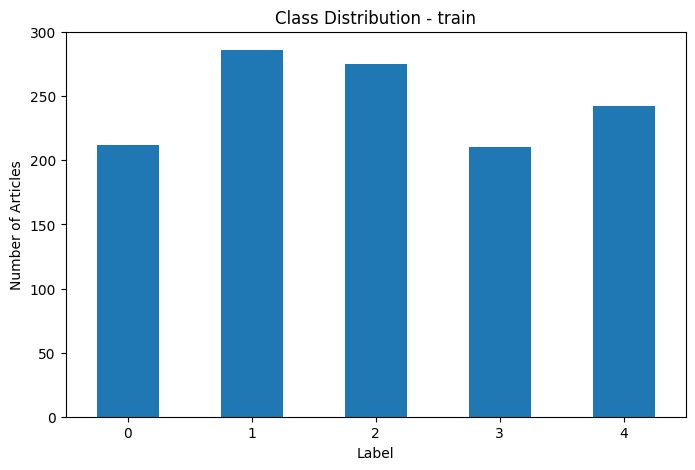

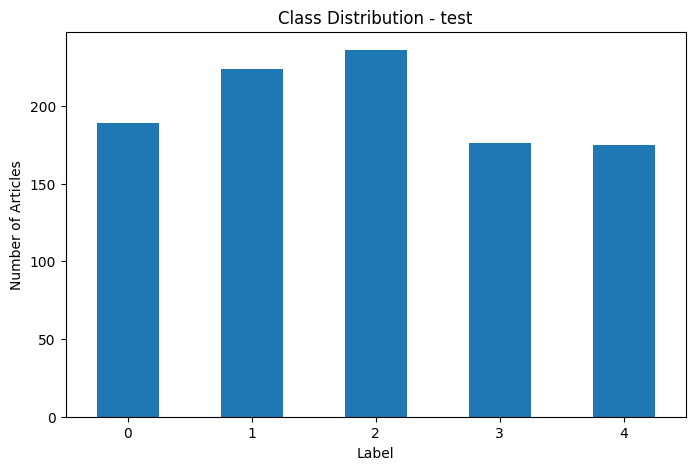

In [ ]:
for split, df in dfs.items():
    counts = df["label"].value_counts().sort_index()

    plt.figure(figsize=(8, 5))
    counts.plot(kind="bar")
    plt.title(f"Class Distribution - {split}")
    plt.xlabel("Label")
    plt.ylabel("Number of Articles")
    plt.xticks(rotation=0)
    plt.show()

In [ ]:
for split, df in dfs.items():

    df["char_count"] = df["text"].astype(str).str.len()
    df["word_count"] = df["text"].astype(str).str.split().str.len()
    df["sentence_count"] = (
        df["text"]
        .astype(str)
        .str.count(r"[.!?]")
    )

    print(f"\n{'='*60}")
    print(f"Text statistics - {split}")
    print(f"{'='*60}")

    print("\nCharacter count:")
    print(df["char_count"].describe())

    print("\nWord count:")
    print(df["word_count"].describe())

    print("\nSentence count:")
    print(df["sentence_count"].describe())


Text statistics - train

Character count:
count     1225.000000
mean      2288.946122
std       1508.459075
min        501.000000
25%       1444.000000
50%       1976.000000
75%       2810.000000
max      25483.000000
Name: char_count, dtype: float64

Word count:
count    1225.000000
mean      395.019592
std       268.243377
min        90.000000
25%       249.000000
50%       340.000000
75%       485.000000
max      4492.000000
Name: word_count, dtype: float64

Sentence count:
count    1225.000000
mean       20.023673
std        15.002949
min         4.000000
25%        13.000000
50%        18.000000
75%        24.000000
max       250.000000
Name: sentence_count, dtype: float64

Text statistics - test

Character count:
count     1000.000000
mean      2231.074000
std       1163.066925
min        719.000000
25%       1446.750000
50%       1951.500000
75%       2778.250000
max      16158.000000
Name: char_count, dtype: float64

Word count:
count    1000.000000
mean      384.508000
std   

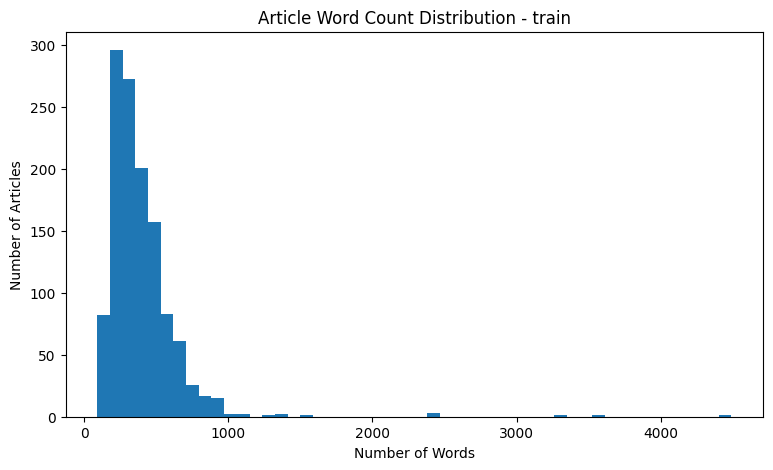

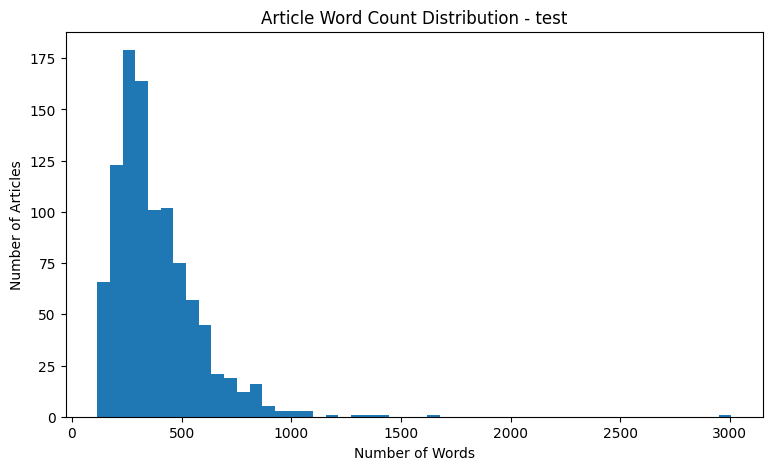

In [ ]:
for split, df in dfs.items():

    plt.figure(figsize=(9, 5))
    plt.hist(df["word_count"], bins=50)
    plt.title(f"Article Word Count Distribution - {split}")
    plt.xlabel("Number of Words")
    plt.ylabel("Number of Articles")
    plt.show()

In [ ]:
for split, df in dfs.items():

    print(f"\nText length by class - {split}")

    display(
        df.groupby("label")["word_count"]
        .agg(["count", "mean", "median", "min", "max", "std"])
        .round(2)
    )



Text length by class - train


,count,mean,median,min,max,std
label,,,,,,
0,212,516.90,469.0,165,1549,218.01
1,286,341.30,308.0,142,912,145.11
2,275,334.93,297.0,117,1387,170.89
3,210,337.14,260.0,144,3570,328.78
4,242,470.24,439.0,90,4492,377.86



Text length by class - test


,count,mean,median,min,max,std
label,,,,,,
0,189,496.66,435.0,188,3007,267.27
1,224,325.10,297.5,145,902,128.12
2,236,337.94,292.0,116,1671,213.28
3,176,338.31,280.5,147,1300,171.88
4,175,448.69,459.0,157,1212,153.93


<Figure size 900x500 with 0 Axes>

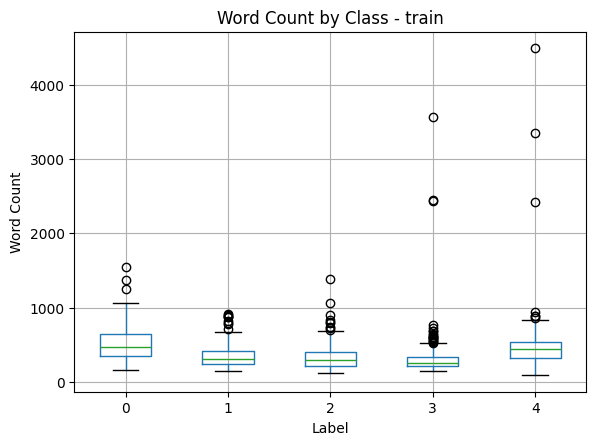

<Figure size 900x500 with 0 Axes>

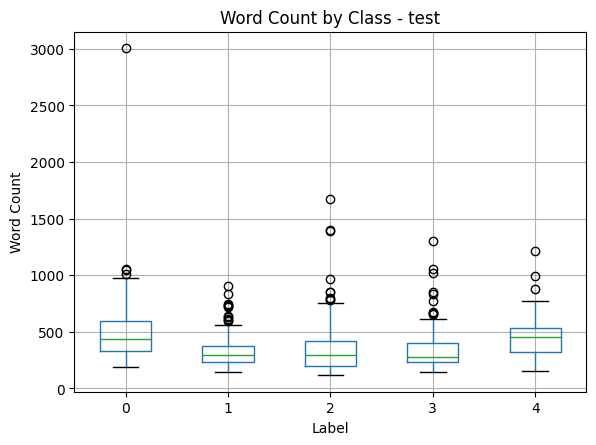

In [ ]:
for split, df in dfs.items():

    plt.figure(figsize=(9, 5))

    df.boxplot(
        column="word_count",
        by="label"
    )

    plt.title(f"Word Count by Class - {split}")
    plt.suptitle("")
    plt.xlabel("Label")
    plt.ylabel("Word Count")
    plt.show()

In [ ]:
for split, df in dfs.items():

    print(f"\n{'='*70}")
    print(f"Examples by class - {split}")
    print(f"{'='*70}")

    for label in sorted(df["label"].unique()):

        print(f"\n--- Label {label} ---")

        examples = df[df["label"] == label]["text"].head(3)

        for i, text in enumerate(examples, 1):
            print(f"\nExample {i}:")
            print(text[:500], "...")



Examples by class - train

--- Label 0 ---

Example 1:
tough rules for ringtone sellers firms that flout rules on how ringtones and other mobile extras are sold could be cut off from all uk phone networks.  the rules allow offenders to be cut off if they do not let consumers know exactly what they get for their money and how to turn off the services. the first month under the new rules has seen at least ten firms suspended while they clean up the way they work. the rules have been brought in to ensure that the problems plaguing net users do not spre ...

Example 2:
broadband set to revolutionise tv bt is starting its push into television with plans to offer tv over broadband.  as a telecoms company  bt is moving to a content distribution strategy  andrew burke  chief of bt s new entertainment unit told the iptv world forum.  we want to be an entertainment facilitator   he said on the opening day of the london conference. the bbc is also trialling a service to play programmes over the 

In [ ]:
for split, df in dfs.items():

    print(f"\nShort articles - {split}")

    short_articles = df[df["word_count"] < 20]

    print("Number of articles with <20 words:",
          len(short_articles))

    display(
        short_articles[
            ["text", "label", "word_count"]
        ].head(10)
    )




Short articles - train
Number of articles with <20 words: 0


,text,label,word_count



Short articles - test
Number of articles with <20 words: 0


,text,label,word_count


In [ ]:
for split, df in dfs.items():

    print(f"\nLongest articles - {split}")

    display(
        df.nlargest(10, "word_count")[
            ["text", "label", "word_count"]
        ]
    )


Longest articles - train


,text,label,word_count
756,terror powers expose tyranny the lord chance...,4,4492
196,scissor sisters triumph at brits us band sciss...,3,3570
538,minimum wage increased to £5.05 the minimum wa...,4,3345
806,roundabout continues nostalgia trip the new bi...,3,2448
6,brits debate over urban music joss stone a ...,3,2430
968,kilroy launches veritas party ex-bbc chat sh...,4,2427
62,apple laptop is greatest gadget the apple po...,0,1549
677,parry firm over gerrard listen to the full int...,2,1387
726,call for action on internet scam phone compani...,0,1368
453,apple laptop is greatest gadget the apple po...,0,1252



Longest articles - test


,text,label,word_count
875,losing yourself in online gaming online role p...,0,3007
351,all black magic: new zealand rugby playing col...,2,1671
854,nadal puts spain 2-0 up result: nadal 6-7 (6/8...,2,1398
553,parry puts gerrard above money listen to the...,2,1388
11,franz man seeks government help franz ferdinan...,3,1300
999,what the election should really be about a ge...,4,1212
914,be careful how you code a new european directi...,0,1056
449,how the academy awards flourished the 77th ann...,3,1055
108,podcasts mark rise of diy radio an apple ipod ...,0,1045
121,critics back aviator for oscars martin scorses...,3,1024


In [ ]:
summary = []

for split, df in dfs.items():

    summary.append({
        "split": split,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_values": df.isnull().sum().sum(),
        "duplicates": df.duplicated().sum(),
        "mean_words": df["word_count"].mean(),
        "median_words": df["word_count"].median(),
        "min_words": df["word_count"].min(),
        "max_words": df["word_count"].max(),
        "num_classes": df["label"].nunique()
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,split,rows,columns,missing_values,duplicates,mean_words,median_words,min_words,max_words,num_classes
0,train,1225,6,0,31,395.019592,340.0,90,4492,5
1,test,1000,6,0,26,384.508000,334.0,116,3007,5


#Preprocessing





In [ ]:


def clean_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)

    # Remove HTML
    text = re.sub(r"<.*?>", " ", text)

    # Keep letters and spaces
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    return text
train_df = dfs["train"]
test_df = dfs["test"]

train_df["clean_text"] = train_df["text"].apply(clean_text)
test_df["clean_text"] = test_df["text"].apply(clean_text)

train_df.drop_duplicates( subset=["clean_text"] ).reset_index(drop=True)
test_df.drop_duplicates( subset=["clean_text"] ).reset_index(drop=True)

X_text_train = train_df["clean_text"].tolist()
X_text_test = test_df["clean_text"].tolist()

y_train = train_df["label"].values
y_test = test_df["label"].values

print(X_text_train[0])
print("Label:", y_train[0])

wales want rugby league training wales could follow england s lead by training with a rugby league club england have already had a three day session with leeds rhinos and wales are thought to be interested in a similar clinic with rivals st helens saints coach ian millward has given his approval but if it does happen it is unlikely to be this season saints have a week s training in portugal next week while wales will play england in the opening six nations match on february we have had an approach from wales confirmed a saints spokesman it s in the very early stages but it is something we are giving serious consideration to st helens who are proud of their welsh connections are obvious partners for the welsh rugby union despite a spat in over the collapse of kieron cunningham s proposed move to union side swansea a similar cross code deal that took iestyn harris from leeds to cardiff in did go through before the talented stand off returned to the man code with bradford bulls kel coslet

### Method 1: TF-IDF


In [ ]:
tfidf = TfidfVectorizer(
    max_features=20000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_text_train)

X_test_tfidf = tfidf.transform(X_text_test)

print("X_train_tfidf:", X_train_tfidf.shape)
print("X_test_tfidf :", X_test_tfidf.shape)

# print("Vocabulary size:", len(tfidf.vocabulary_)

X_train_tfidf: (1225, 20000)
X_test_tfidf : (1000, 20000)


### Method 2: Bert

In [ ]:

model_name = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)
bert_model = AutoModel.from_pretrained(model_name)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

bert_model = bert_model.to(device)
bert_model.eval()

print("Using device:", device)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Using device: cuda


In [ ]:
# BERT preprocessing/tokenization
bert_train_text = train_df["text"].astype(str).tolist()
bert_test_text = test_df["text"].astype(str).tolist()

train_encodings = tokenizer(
    bert_train_text,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

test_encodings = tokenizer(
    bert_test_text,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

print(train_encodings["input_ids"].shape)
print(test_encodings["input_ids"].shape)

torch.Size([1225, 256])
torch.Size([1000, 256])


In [ ]:
# Extract BERT embeddings
from torch.utils.data import DataLoader, TensorDataset

def get_bert_embeddings(encodings, model, batch_size=16):

    dataset = TensorDataset(
        encodings["input_ids"],
        encodings["attention_mask"]
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size
    )

    embeddings = []

    model.eval()

    with torch.no_grad():

        for input_ids, attention_mask in loader:

            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # CLS embedding
            cls_embedding = outputs.last_hidden_state[:, 0, :]

            embeddings.append(
                cls_embedding.cpu().numpy()
            )

    return np.vstack(embeddings)

In [ ]:
X_train_bert = get_bert_embeddings(
    train_encodings,
    bert_model,
    batch_size=16
)

X_test_bert = get_bert_embeddings(
    test_encodings,
    bert_model,
    batch_size=16
)

print("X_train_bert:", X_train_bert.shape)
print("X_test_bert :", X_test_bert.shape)

X_train_bert: (1225, 768)
X_test_bert : (1000, 768)


# Model

Evaluation function


In [ ]:
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from modules.evaluation import evaluate_torch_model
from modules.naive_bayes import GaussianNaiveBayes
from modules.decision_tree import train_decision_tree
from modules.mlp import MLP


def eval(model, X, y, criterion):
    return evaluate_torch_model(model, X, y, criterion, device=DEVICE)


Model 1: Naive bayes

In [ ]:

clf = GaussianNaiveBayes()


In [ ]:
X_train_tfidf.shape

(1225, 100)

In [ ]:
y_train.shape

(1225,)

In [ ]:
X_train_bert.shape

(1225, 768)

In [37]:
clf = GaussianNB()
clf.fit(X_train_tfidf.toarray(), y_train)
y_pred = clf.predict(X_test_tfidf.toarray())
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.87      0.95      0.91       189
           1       0.97      0.91      0.94       224
           2       1.00      0.99      0.99       236
           3       0.99      0.84      0.91       176
           4       0.86      0.98      0.91       175

    accuracy                           0.94      1000
   macro avg       0.94      0.93      0.93      1000
weighted avg       0.94      0.94      0.94      1000



In [ ]:
clf = GaussianNaiveBayes()
clf.fit(X_train_tfidf.toarray(), y_train)
y_pred = clf.predict(X_test_tfidf.toarray())
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.87      0.95      0.91       189
           1       0.97      0.91      0.94       224
           2       1.00      0.99      0.99       236
           3       0.99      0.84      0.91       176
           4       0.86      0.98      0.91       175

    accuracy                           0.94      1000
   macro avg       0.94      0.93      0.93      1000
weighted avg       0.94      0.94      0.94      1000



Model 2: Decision tree

In [ ]:
clf, y_pred = train_decision_tree(
    X_train_tfidf,
    y_train,
    X_test_tfidf
)
print(classification_report(y_test, y_pred))


In [ ]:
clf, y_pred = train_decision_tree(
    X_train_bert,
    y_train,
    X_test_bert
)
print(classification_report(y_test, y_pred))


Model 3: MLP

In [ ]:
model_mlp_tfidf = MLP(X_train_tfidf.shape[1], 5).to(DEVICE)
history_loss_tfidf, history_accuracy_tfidf = model_mlp_tfidf.trainer(
    X_train_tfidf.toarray(),
    y_train,
    epochs=60,
    device=DEVICE
)

_, accuracy_score_model_mlp_tfidf, report_model_mlp_tfidf = eval(
    model_mlp_tfidf,
    X_test_tfidf.toarray(),
    y_test,
    nn.CrossEntropyLoss()
)

print('=' * 10 + ' Result ' + '=' * 10)
print(report_model_mlp_tfidf)
print(accuracy_score_model_mlp_tfidf)

sns.lineplot(x=range(len(history_accuracy_tfidf)), y=history_accuracy_tfidf)


In [ ]:
model_mlp_bert = MLP(X_train_bert.shape[1], 5).to(DEVICE)
history_loss_bert, history_accuracy_bert = model_mlp_bert.trainer(
    X_train_bert,
    y_train,
    epochs=60,
    device=DEVICE
)

_, accuracy_score_model_mlp_bert, report_model_mlp_bert = eval(
    model_mlp_bert,
    X_test_bert,
    y_test,
    nn.CrossEntropyLoss()
)

print('=' * 10 + ' Result ' + '=' * 10)
print(report_model_mlp_bert)
print(accuracy_score_model_mlp_bert)
